# Training notebook

Step-by-step training of one experiment. Run top to bottom.

* Settings live in **cell 1** (`Config`). Change `exp_name` for every new experiment.
* `SMOKE = True` runs a few batches per epoch to check the pipeline before a full run.
* Outputs go to `runs/<exp_name>/` (`config.json`, `log.csv`, `best.pt`, `last.pt`).
* Self-contained: helpers (optimizer, schedule, evaluation, checkpoints) are in section 0; the training loop is written out in sections 5–6.

In [1]:
%load_ext autoreload
%autoreload 2

import csv, json, math, random, time
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F

from config import CLASS_NAMES, NUM_CLASSES, Config
from data import build_loaders, build_val_jpeg_loader
from geo_aug_data import GeoConfig, build_geo_loaders
from model import build_model, count_params
from helpers import seed_everything, get_device, build_optimizer, build_scheduler, evaluate, format_cm, save_checkpoint, load_model

## 1. Config

In [ ]:
# Set training config here

cfg = GeoConfig(exp_name="model_4",
    crop_size=256, 
    epochs=50,
    jpeg_p=0.7, 
    jpeg_q=(80, 95), 
    jpeg_subsampling=(0, 2)
    )
SMOKE = False # Set to true for smoke test: 5 train / 3 val batches per epoch (pipeline check only)
RESUME = False # If True: continue from runs/<exp_name>/last.pt

seed_everything(cfg.seed) # Set everything to fixed seed
device = get_device()
out = cfg.out_dir
out.mkdir(parents=True, exist_ok=True)
(out / "config.json").write_text(json.dumps(cfg.to_dict(), indent=2))
print(device, out)

mps /Users/clayton/Desktop/NTU/Courses/CE7454/dev_phase/runs/model_4


## 2. Data

In [3]:
# train_dl, val_dl = build_loaders(cfg)
# val_jpeg_dl = build_val_jpeg_loader(cfg) 
train_dl, val_dl, val_jpeg_dl = build_geo_loaders(cfg)
x, y = next(iter(train_dl))
# print data details
print(f"train: {len(train_dl.dataset)} imgs, {len(train_dl)} batches/epoch, batch {tuple(x.shape)}")
print(f"val:   {len(val_dl.dataset)} imgs (val_mode={cfg.val_mode})")
print("labels in batch:", y.bincount(minlength=3).tolist())

train: 13500 imgs, 210 batches/epoch, batch (64, 3, 256, 256)
val:   1500 imgs (val_mode=full)
labels in batch: [18, 25, 21]


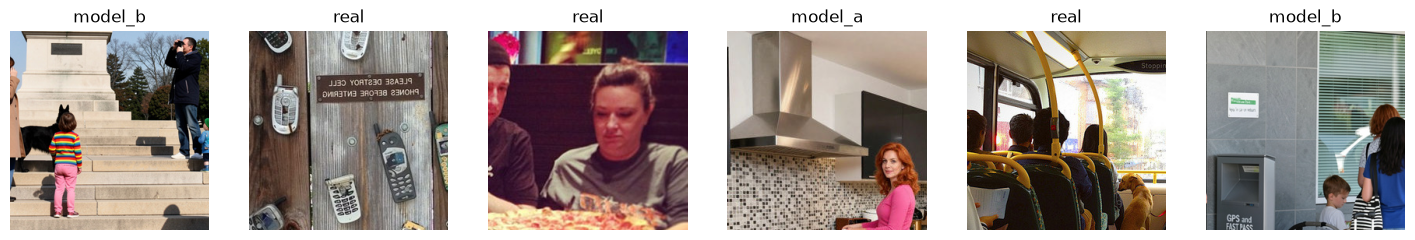

In [4]:
# look at a few training crops
fig, axes = plt.subplots(1, 6, figsize=(18, 3))
for ax, img, lab in zip(axes, x, y):
    ax.imshow(((img.permute(1, 2, 0) + 1) / 2).clamp(0, 1))
    ax.set_title(CLASS_NAMES[lab]); ax.axis("off")
plt.show()

## 3. Model

In [5]:
# Setting up the model
model = build_model().to(device)
print(f"resnet_s1  params={count_params(model)/1e6:.2f}M")
with torch.no_grad():
    print("logits shape:", model(x[:2].to(device)).shape)


resnet_s1  params=2.81M
logits shape: torch.Size([2, 3])


## 4. Optimizer and LR schedule

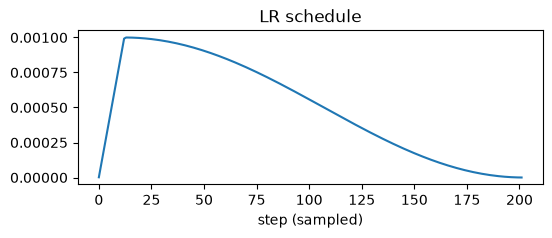

In [6]:
opt = build_optimizer(model, cfg)
sched = build_scheduler(opt, cfg, len(train_dl))

start_epoch, best_acc, history = 0, 0.0, []
if RESUME and (out / "last.pt").exists():
    ckpt = torch.load(out / "last.pt", map_location=device, weights_only=False)
    model.load_state_dict(ckpt["model"]); opt.load_state_dict(ckpt["opt"]); sched.load_state_dict(ckpt["sched"])
    start_epoch, best_acc = ckpt["epoch"] + 1, ckpt["best_acc"]
    print(f"resumed at epoch {start_epoch}, best acc {best_acc:.4f}")

# preview of the schedule (warm-up then cosine)
steps = len(train_dl) * cfg.epochs
lrs = [cfg.lr * sched.lr_lambdas[0](s) for s in range(0, steps, max(1, steps // 200))]
plt.figure(figsize=(6, 2)); plt.plot(lrs); plt.title("LR schedule"); plt.xlabel("step (sampled)"); plt.show()

## 5. Training step

In [7]:
def train_one_epoch(model, loader, max_batches=None):
    model.train()
    tot_loss, correct, n = 0.0, 0, 0
    for i, (x, y) in enumerate(loader):
        if max_batches is not None and i >= max_batches:
            break
        x, y = x.to(device), y.to(device)

        logits = model(x)
        loss = F.cross_entropy(logits, y, label_smoothing=cfg.label_smoothing)

        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()
        sched.step()                      # per-step schedule

        tot_loss += loss.item() * x.shape[0]
        correct += (logits.argmax(1) == y).sum().item()
        n += x.shape[0]
    return {"loss": tot_loss / n, "acc": correct / n}

## 6. Training loop

In [8]:
max_tr, max_val = (5, 3) if SMOKE else (None, None)
log_path = out / "log.csv"
if not (RESUME and log_path.exists()):
    with open(log_path, "w", newline="") as f:
        csv.writer(f).writerow(["epoch", "lr", "train_loss", "train_acc", "val_loss", "val_acc",
                                *[f"val_acc_{c}" for c in CLASS_NAMES], "val_jpeg_loss", "val_jpeg_acc", 
                                *[f"val_jpeg_acc_{c}" for c in CLASS_NAMES], "time_s"])

for epoch in range(start_epoch, cfg.epochs):
    t0 = time.time()
    lr = opt.param_groups[0]["lr"]
    tr = train_one_epoch(model, train_dl, max_tr)
    va = evaluate(model, val_dl, device, max_val)
    vj = evaluate(model, val_jpeg_dl, device, max_val) # Evaluate on validation (4, 2, 0) as well
    dt = time.time() - t0

    history.append({"epoch": epoch, "lr": lr, "train_loss": tr["loss"], "train_acc": tr["acc"],
                    "val_loss": va["loss"], "val_acc": va["acc"], "val_jpeg_loss": vj["loss"], "val_jpeg_acc": vj["acc"], "per_class": va["per_class"]})
    with open(log_path, "a", newline="") as f:
        csv.writer(f).writerow([epoch, f"{lr:.2e}", f"{tr['loss']:.4f}", f"{tr['acc']:.4f}",
                                f"{va['loss']:.4f}", f"{va['acc']:.4f}",
                                *[f"{a:.4f}" for a in va["per_class"]], f"{vj['loss']:.4f}", 
                                f"{vj['acc']:.4f}", *[f"{a:.4f}" for a in vj["per_class"]], 
                                f"{dt:.0f}"])

        is_best = vj["acc"] > best_acc
    if is_best:
        best_acc = vj["acc"]
        save_checkpoint(out / "best.pt", model, opt, sched, epoch, best_acc, cfg)
    save_checkpoint(out / "last.pt", model, opt, sched, epoch, best_acc, cfg)

    print(f"ep {epoch:3d} | lr {lr:.2e} | train {tr['loss']:.4f} / {tr['acc']:.4f} | "
          f"val {va['loss']:.4f} / {va['acc']:.4f} ({' '.join(f'{a:.3f}' for a in va['per_class'])}) "
          f"| jpeg {vj['acc']:.4f} ({' '.join(f'{a:.3f}' for a in vj['per_class'])}) "
          f"| {dt:.0f}s{'  *' if is_best else ''}")

print(f"best val acc {best_acc:.4f}")

ep   0 | lr 1.59e-06 | train 1.0833 / 0.4045 | val 1.0260 / 0.5120 (0.592 0.238 0.706) | jpeg 0.4940 (0.558 0.208 0.716) | 124s  *
ep   1 | lr 3.35e-04 | train 1.0213 / 0.4897 | val 0.9694 / 0.5100 (0.622 0.514 0.394) | jpeg 0.5273 (0.478 0.654 0.450) | 114s  *
ep   2 | lr 6.68e-04 | train 0.9939 / 0.5189 | val 1.0278 / 0.5100 (0.652 0.102 0.776) | jpeg 0.4940 (0.516 0.142 0.824) | 113s
ep   3 | lr 1.00e-03 | train 0.9834 / 0.5295 | val 0.9054 / 0.5853 (0.764 0.674 0.318) | jpeg 0.5513 (0.628 0.734 0.292) | 104s  *
ep   4 | lr 9.99e-04 | train 0.9641 / 0.5532 | val 0.9290 / 0.5527 (0.518 0.856 0.284) | jpeg 0.5007 (0.362 0.926 0.214) | 103s
ep   5 | lr 9.96e-04 | train 0.9499 / 0.5680 | val 1.1067 / 0.3833 (0.988 0.124 0.038) | jpeg 0.4373 (0.968 0.224 0.120) | 103s
ep   6 | lr 9.90e-04 | train 0.9302 / 0.5857 | val 0.9415 / 0.5327 (0.920 0.246 0.432) | jpeg 0.5860 (0.812 0.374 0.572) | 103s  *
ep   7 | lr 9.82e-04 | train 0.9132 / 0.6033 | val 1.0598 / 0.4340 (0.990 0.104 0.208) | jpe

## 7. Learning curves

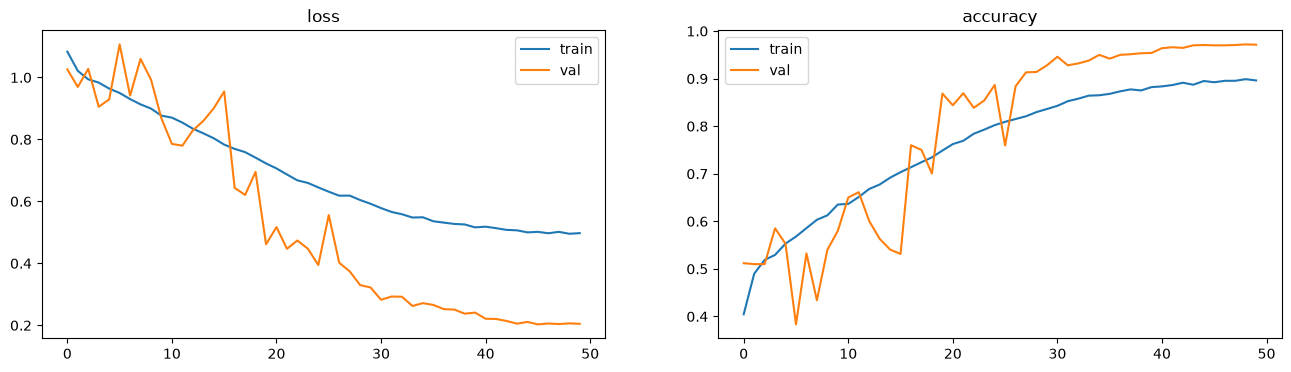

In [11]:
ep = [h["epoch"] for h in history]
fig, ax = plt.subplots(1, 2, figsize=(16, 4))
ax[0].plot(ep, [h["train_loss"] for h in history], label="train")
ax[0].plot(ep, [h["val_loss"] for h in history], label="val"); ax[0].set_title("loss"); ax[0].legend()
ax[1].plot(ep, [h["train_acc"] for h in history], label="train")
ax[1].plot(ep, [h["val_acc"] for h in history], label="val"); ax[1].set_title("accuracy"); ax[1].legend()
plt.show()

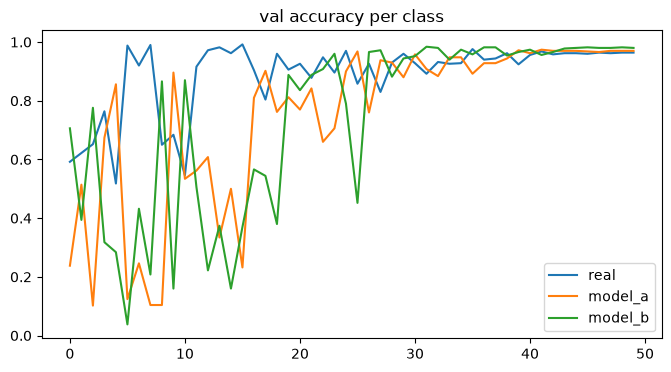

In [15]:
fig, ax = plt.subplots(1, 1, figsize=(8, 4))
for c, name in enumerate(CLASS_NAMES):
    ax.plot(ep, [h["per_class"][c] for h in history], label=name)
ax.set_title("val accuracy per class"); ax.legend()
plt.show()

## 8. Evaluate the best checkpoint

In [10]:
best_model, best_cfg = load_model(out / "best.pt", device)
va = evaluate(best_model, val_dl, device, max_val)
vj = evaluate(best_model, val_jpeg_dl, device, max_val)

print(f"best checkpoint: val acc {va['acc']:.4f}")
print(format_cm(va["cm"]))   # rows = true class, cols = predicted

print(f"best checkpoint: val (q90 4:2:0) acc {vj['acc']:.4f}")
print(format_cm(vj["cm"]))

best checkpoint: val acc 0.9707
                  real model_a model_b
  true    real     481       8      11
  true model_a      10     485       5
  true model_b       9       1     490
best checkpoint: val (q90 4:2:0) acc 0.9300
                  real model_a model_b
  true    real     466      14      20
  true model_a      26     460      14
  true model_b      15      16     469


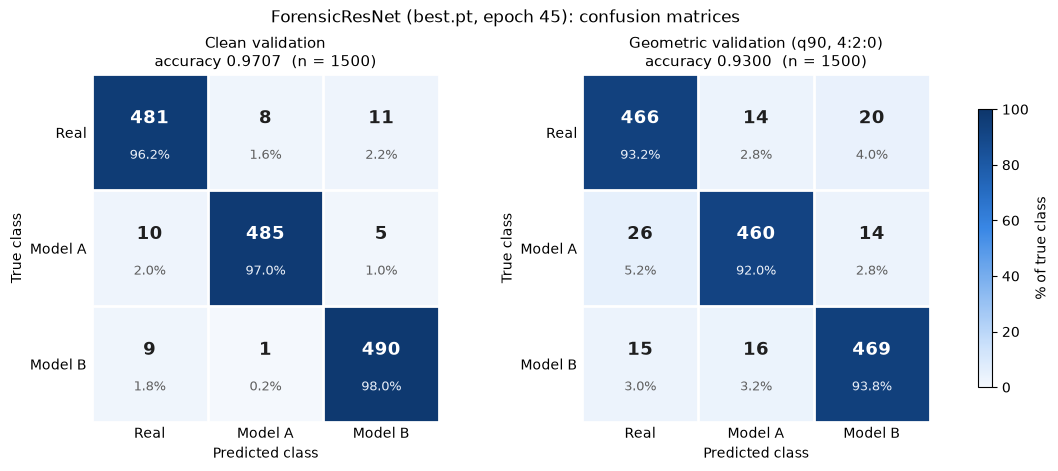

saved /Users/clayton/Desktop/NTU/Courses/CE7454/dev_phase/runs/model_4/confusion_matrix.png


In [17]:
# Confusion matrices of the best checkpoint (uses `va` / `vj` from the cell above); saved as a PNG for the report
from matplotlib.colors import LinearSegmentedColormap

best_epoch = torch.load(out / "best.pt", map_location="cpu", weights_only=False)["epoch"]
cmap = LinearSegmentedColormap.from_list(   # single-hue sequential ramp: light = 0%, dark = 100%
    "blues", ["#f4f8fd", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
labels = ["Real", "Model A", "Model B"]
panels = [("Clean validation", va), ("Geometric validation (q90, 4:2:0)", vj)]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), constrained_layout=True)
for ax, (title, res) in zip(axes, panels):
    cm = res["cm"].numpy()
    pct = cm / cm.sum(1, keepdims=True) * 100   # row-normalised: % of each true class
    im = ax.imshow(pct, cmap=cmap, vmin=0, vmax=100)
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            dark = pct[i, j] > 55
            ax.text(j, i - 0.12, f"{cm[i, j]}", ha="center", va="center", fontsize=13,
                    fontweight="bold", color="white" if dark else "#1f1f1f")
            ax.text(j, i + 0.2, f"{pct[i, j]:.1f}%", ha="center", va="center", fontsize=9,
                    color="#e8eef7" if dark else "#5f5f5f")
    ax.set_xticks(range(NUM_CLASSES), labels); ax.set_yticks(range(NUM_CLASSES), labels)
    ax.set_xlabel("Predicted class"); ax.set_ylabel("True class")
    ax.set_title(f"{title}\naccuracy {res['acc']:.4f}  (n = {cm.sum()})", fontsize=11)
    ax.set_xticks(np.arange(-0.5, NUM_CLASSES), minor=True); ax.set_yticks(np.arange(-0.5, NUM_CLASSES), minor=True)
    ax.grid(which="minor", color="white", linewidth=2)   # 2px gap between cells
    ax.tick_params(which="both", length=0)
    for s in ax.spines.values():
        s.set_visible(False)
fig.colorbar(im, ax=axes, shrink=0.8, label="% of true class")
fig.suptitle(f"ForensicResNet (best.pt, epoch {best_epoch + 1}): confusion matrices", fontsize=12)
fig.savefig(out / "confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()
print(f"saved {out / 'confusion_matrix.png'}")

## 9. Reuse

`best_model` (or `model`, the last epoch) stays in memory for further analysis.
A trained model can be reloaded later with `load_model` from `helpers.py`:

```python
model, cfg = load_model("runs/model_4/best.pt", device)
```

Test-set predictions are written by `predict_test.py` (defaults to `runs/model_4/best.pt` and `test/`).